# GSE78144

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-05-17
> - Modified: 2023-09-27

# 1. Experimental Design

> Comparison of transcriptional profiles between naive, primed and ground state pluripotency in mouse embryonic stem cells of the same genetic background.
> - Ghimire, S., Van der Jeught, M., Neupane, J. et al. Comparative analysis of naive, primed and ground state pluripotency in mouse embryonic stem cells originating from the same genetic background. Sci Rep 8, 5884 (2018). https://doi.org/10.1038/s41598-018-24051-5.
> - Agilent SurePrint G3 Unrestricted Mouse Gene Expression 8 × 60 K Microarrays (G4858A-028005)
> - Agilent G2565CA Microarray Scanner
> - Ghent University Hospital

| Sample | Cell | Tissue | Strain | Treatment | Pluripotency State | Passage | Replicate |
| - | - | - | - | - | - | - | - |
| LIF serum | ESC | Embryonic stem cells | 129/Ola | LIF +serum | Naive | P23,P24,P26,P26 | rep1~4 |
| mEpiSCs | ESC | Embryonic stem cells | 129/Ola | Activin A + bFGF | Primed | P24,P24,P24,P28 | rep1~4 |
| 2i mESCs | ESC | Embryonic stem cells | 129/Ola | 2i+LIF | Ground | P24,P22,P23,P22 | rep1~4 |
| 2iSB mESCs | ESC | Embryonic stem cells | 129/Ola | 2i+SB431542+LIF | Ground | P22,P17,P19,P24 | rep1~4 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(GEOquery))
suppressPackageStartupMessages(library(pheatmap))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Download Data

In [2]:
gse_id <- "GSE78144"
data_dir <- file.path("~/dataset_1/expression_dataset/array", gse_id)
dir.create(data_dir, showWarnings = FALSE)

In [ ]:
eSet <- getGEO(
    GEO = gse_id, destdir = data_dir,
    AnnotGPL = TRUE, getGPL = FALSE)[[1]]
eSet

Found 1 file(s)

GSE78144_series_matrix.txt.gz

Annotation GPL not available, so will use submitter GPL instead



ExpressionSet (storageMode: lockedEnvironment)
assayData: 42316 features, 16 samples 
  element names: exprs 
protocolData: none
phenoData
  sampleNames: GSM2067949 GSM2067950 ... GSM2067964 (16 total)
  varLabels: title geo_accession ... strain:ch1 (42 total)
  varMetadata: labelDescription
featureData
  featureNames: A_30_P01017425 A_30_P01017426 ... A_66_P140976 (42316
    total)
  fvarLabels: ID SPOT_ID ... SEQUENCE (17 total)
  fvarMetadata: Column Description labelDescription
experimentData: use 'experimentData(object)'
Annotation: GPL10787 

In [4]:
exprs(eSet)[1:6, 1:6]

,GSM2067949,GSM2067950,GSM2067951,GSM2067952,GSM2067953,GSM2067954
A_30_P01017425,6.847,6.674,6.230,5.775,6.995,7.278
A_30_P01017426,7.095,7.006,5.920,5.893,6.291,6.031
A_30_P01017427,5.850,5.652,4.167,5.086,5.882,5.729
A_30_P01017428,7.957,8.173,7.545,7.604,8.724,9.037
A_30_P01017432,6.662,6.685,6.230,5.681,5.804,6.065
A_30_P01017433,6.938,6.620,5.955,5.648,5.903,6.372


In [6]:
pdata <- pData(eSet) |> 
    tidyr::separate(
        title, into = c("ID", "Replicate"), 
        sep = "replicate ", remove = FALSE) |>
    dplyr::rename(
        Source = source_name_ch1, 
        Group = `pluripotency state:ch1`,
        Treatment = `protocol:ch1`) |>
    dplyr::select("title", "Source", "Treatment", "Group", "Replicate") |>
    mutate(
        Source = factor(
            Source, levels = c(
                "LIF serum", "mEpiSCs", "2i mESCs", "2iSB mESCs")),
        Group = factor(
            Group, levels = c("Naive", "Primed", "Ground")))
pdata

,title,Source,Treatment,Group,Replicate
,<chr>,<fct>,<chr>,<fct>,<chr>
GSM2067949,LIF serum replicate 1,LIF serum,LIF +serum,Naive,1
GSM2067950,LIF serum replicate 2,LIF serum,LIF +serum,Naive,2
GSM2067951,LIF serum replicate 3,LIF serum,LIF +serum,Naive,3
GSM2067952,LIF serum replicate 4,LIF serum,LIF +serum,Naive,4
GSM2067953,mEpiSCs replicate 1,mEpiSCs,Activin A + bFGF,Primed,1
GSM2067954,mEpiSCs replicate 2,mEpiSCs,Activin A + bFGF,Primed,2
GSM2067955,mEpiSCs replicate 3,mEpiSCs,Activin A + bFGF,Primed,3
GSM2067956,mEpiSCs replicate 4,mEpiSCs,Activin A + bFGF,Primed,4
GSM2067957,2i mESCs replicate 1,2i mESCs,2i+LIF,Ground,1


# 3. Convert Probe to Symbol

[Agilent expression array gene information](https://earray.chem.agilent.com/earray/catalogGeneLists.do?action=displaylist)

In [17]:
probe2symbol <- file.path(
    data_dir, "SurePrint_G3_Mouse_GE_8x60K_Microarray.txt") |> 
    data.table::fread(header = TRUE, sep = "\t") |>
    dplyr::select("ProbeID", "GeneSymbol") |>
    dplyr::filter(GeneSymbol != "" & !is.na(GeneSymbol)) |>
    dplyr::distinct()

head(probe2symbol)

ProbeID,GeneSymbol
<chr>,<chr>
A_55_P2347073,AI662501
A_55_P2251379,AV313155
A_55_P2395179,AA408954
A_55_P2207618,AA414993
A_55_P2389533,AA517446
A_55_P2277014,AA522020


In [18]:
exprMat <- exprs(eSet) |> 
    as.data.frame() |> 
    rownames_to_column("ProbeID") |>
    inner_join(probe2symbol, by = "ProbeID") |>
    filter(GeneSymbol != "" & !is.na(GeneSymbol)) |>
    group_by(GeneSymbol) |>
    summarise(across(where(is.numeric), \(x) max(x, na.rm = TRUE))) |>
    column_to_rownames("GeneSymbol") |>
    as.matrix()

In [19]:
exprMat[1:6, 1:6]

,GSM2067949,GSM2067950,GSM2067951,GSM2067952,GSM2067953,GSM2067954
0610005C13Rik,5.480,4.932,5.019,4.326,5.051,4.734
0610009E02Rik,8.439,8.173,8.394,8.536,8.260,8.152
0610009K14Rik,4.306,4.932,4.938,5.839,4.409,5.039
0610009L18Rik,10.155,10.153,10.603,10.921,9.250,8.970
0610025J13Rik,5.138,4.837,4.493,5.086,4.799,4.400
0610030E20Rik,9.762,10.040,10.141,10.141,10.647,10.924


# 4. Data Exploration

## 1). Quality Control

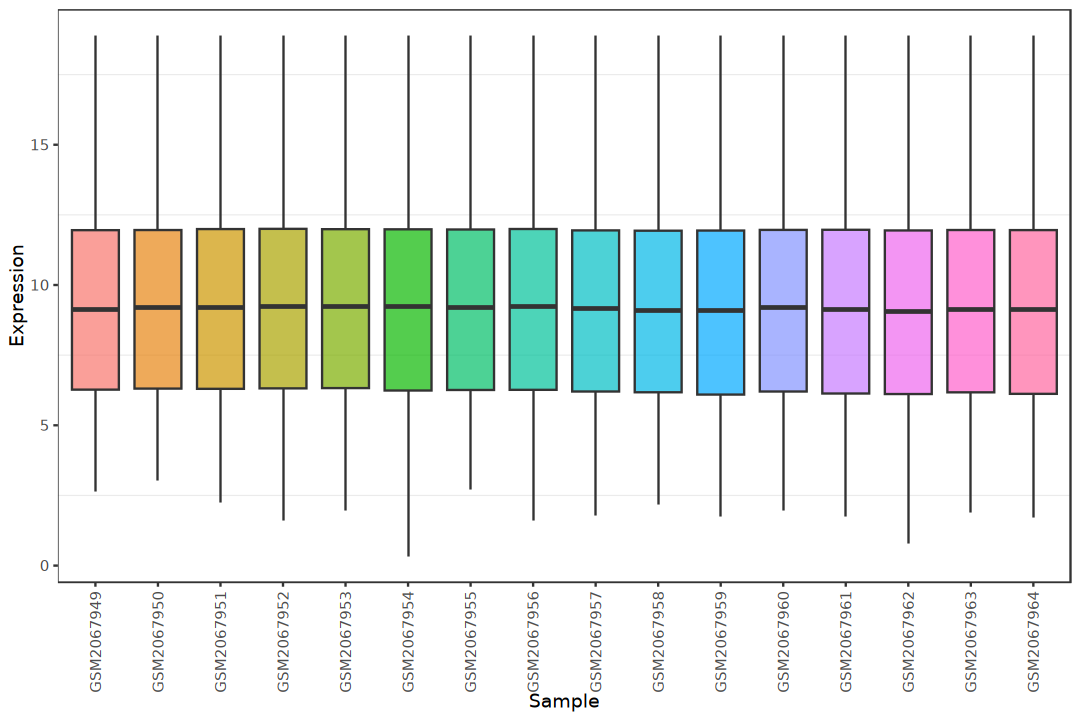

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)
exprMat |> as.data.frame() |> 
    rownames_to_column("symbol") |>
    pivot_longer(-symbol, names_to = "sample", values_to = "value") |>
    ggplot(aes(x = sample, y = value)) +
        geom_boxplot(aes(fill = sample), alpha = 0.7, outlier.shape = NA) +
        labs(x = 'Sample', y = 'Expression') +
        theme_bw() +
        theme(
            legend.position = "none", 
            panel.grid.major = element_blank(),
            axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1))

## 2). Housekeeping Genes

In [21]:
HOUSEKEEPING_GENES <- readLines(
    "~/reference/Database/Housekeeping_Genes/HOUNKPE_HOUSEKEEPING_GENES.v2026.1.Mm.gmt", 
    warn = FALSE) |> 
    str_split("\t") |>
    (\(x) x[[1]])() |>
    (\(x) x[-c(1,2)])() |>
    unique()

In [22]:
str(HOUSEKEEPING_GENES)

 chr [1:1129] "1600012H06Rik" "1700123O20Rik" "1810009A15Rik" ...


In [24]:
anno_col <- data.frame(row.names = rownames(pdata),
    Source = pdata$Source, Group = pdata$Group)

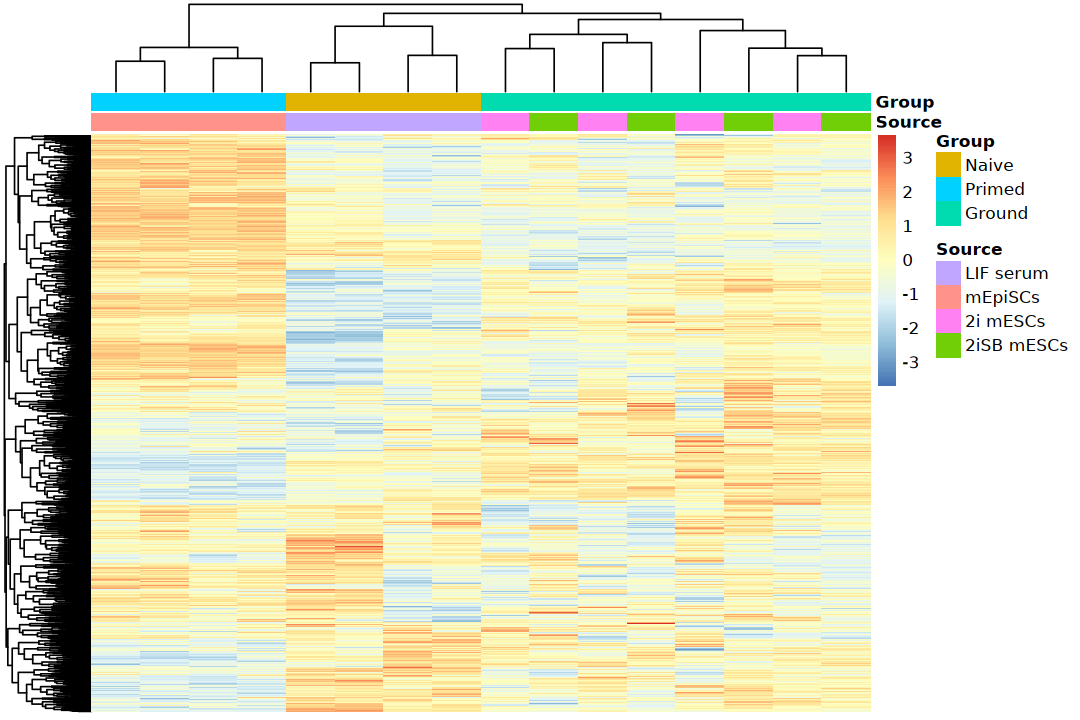

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap(exprMat[rownames(exprMat) %in% HOUSEKEEPING_GENES, ],
         scale = 'row', annotation_col = anno_col,
         show_rownames = FALSE, show_colnames = FALSE)

## 3). PCA

In [26]:
suppressPackageStartupMessages(library(ggfortify))

In [27]:
gene_sd <- apply(exprMat, 1, sd)
top_genes <- names(sort(gene_sd, decreasing = TRUE))[1:1000]

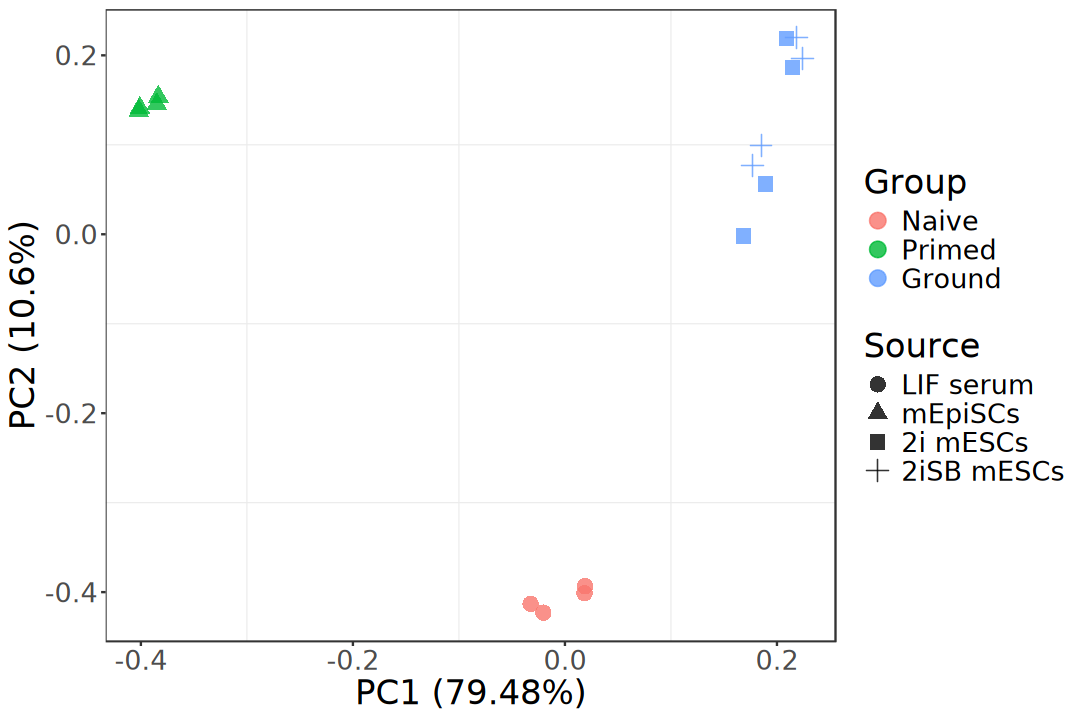

In [29]:
options(repr.plot.width = 9, repr.plot.height = 6)
    exprMat[top_genes, ] |> t() |>
    prcomp() |> 
    autoplot(data = pdata, colour = "Group", shape = "Source", 
        size = 4, alpha = 0.8) +
    theme_bw() +
    theme(
        legend.title = element_text(size = 20),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16), 
        panel.grid.major = element_blank())